# Week 3 — Painting detection (QSD2-W3)

Step-by-step walkthrough of `detect_paintings` from `w3/utils.py`. Images are assumed to be **already denoised**, so by default the notebook uses the clean images in `qsd2_w3/non_augmented`.

**Pipeline** (only edges are used, there is no colour mask)
1. **Edge input**: the image in the chosen colour space / channels (`use_mahalanobis=0`), or the Mahalanobis distance of those channels to the wall (`use_mahalanobis=1`).
2. **Edges**: high-pass filter (Prewitt) on that map + Otsu + closing, so every frame becomes a closed outline.
3. **Week 2 post-processing**: fill holes (closed outlines become solid paintings) + opening (removes edges that enclose nothing).
4. **Largest components** with holes filled (Week 2), extended to keep up to 2 paintings.
5. **Week 2 projection rectangle** for each painting separately, and **ordering** left→right / top→bottom.
6. **Evaluation** on the whole set (pixel precision / recall / F1 / IoU + painting count).

In [ ]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import utils as U

DATA_DIR = Path("..") / "data" / "qsd2_w3"
IMAGE_DIR = DATA_DIR / "non_augmented"   # clean images; use DATA_DIR for the augmented ones

ids = sorted(int(p.stem) for p in IMAGE_DIR.glob("*.jpg"))
images = {i: cv2.imread(str(IMAGE_DIR / f"{i:05d}.jpg")) for i in ids}
gts = {i: cv2.imread(str(IMAGE_DIR / f"{i:05d}.png"), cv2.IMREAD_GRAYSCALE) > 0 for i in ids}
n_gt = {i: cv2.connectedComponents(gts[i].astype(np.uint8))[0] - 1 for i in ids}

print(f"{len(ids)} images | 1 painting: {sum(v == 1 for v in n_gt.values())} | 2 paintings: {sum(v == 2 for v in n_gt.values())}")
U.DEFAULT_PARAMS

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
30 images | 1 painting: 21 | 2 paintings: 9


{'color_space': 'HSV',
 'channels': [1, 2],
 'use_mahalanobis': 0,
 'edge_operator': 'prewitt',
 'blur_ksize': 5,
 'edge_close_frac': 0.02,
 'open_frac': 0.02,
 'min_area_frac': 0.02,
 'min_rel_area': 0.15,
 'min_extent': 0.6,
 'fit_rect': True,
 'proj_frac': 0.5}

In [ ]:
def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def show(panels, cols=None, size=4):
    """panels: list of (title, image). Grey images are shown with a grey colormap."""
    cols = cols or len(panels)
    rows = int(np.ceil(len(panels) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, img) in zip(axes.flat, panels):
        ax.imshow(img, cmap=None if img.ndim == 3 else "gray")
        ax.set_title(title)
    plt.tight_layout()
    plt.show()


def overlay(img, masks, alpha=0.45):
    """Draw each painting mask in a different colour with its order number."""
    colors = [(255, 60, 60), (60, 160, 255), (60, 220, 60), (255, 200, 0)]
    out = rgb(img).copy()
    for k, m in enumerate(masks):
        color = np.array(colors[k % len(colors)])
        sel = m > 0
        out[sel] = ((1 - alpha) * out[sel] + alpha * color).astype(np.uint8)
        contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, contours, -1, color.tolist(), 3)
        x, y, w, h = cv2.boundingRect(m.astype(np.uint8))
        cv2.putText(out, str(k + 1), (x + w // 2, y + h // 2), cv2.FONT_HERSHEY_SIMPLEX,
                    2, (255, 255, 255), 5)
    return out

## 0. Pick an image
Change `IDX` to inspect any image. Interesting ones: `2` (two paintings, one small), `21` (painting colours close to the wall), `29` (two paintings with frame depth).

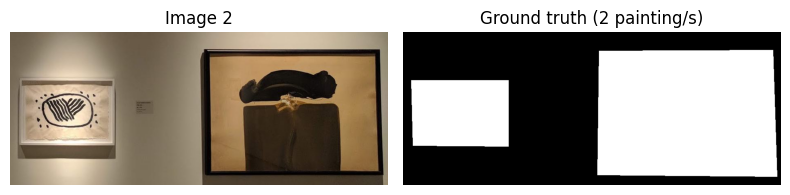

In [ ]:
IDX = 2
img, gt = images[IDX], gts[IDX]
debug = U.detect_paintings_debug(img)
show([(f"Image {IDX}", rgb(img)), (f"Ground truth ({n_gt[IDX]} painting/s)", gt)])

## 1. Edge input
The edges are detected on one of two maps, chosen with `use_mahalanobis`:
- **0** (default): the selected channels of the colour space (HSV S and V by default, so hue changes do not matter). The gradient is computed per channel and the maximum is kept.
- **1**: the Mahalanobis distance of those channels to the wall colour, modelled with a Gaussian fitted on the border pixels (Week 2 idea). It is a single map where the paintings stand out from the wall.

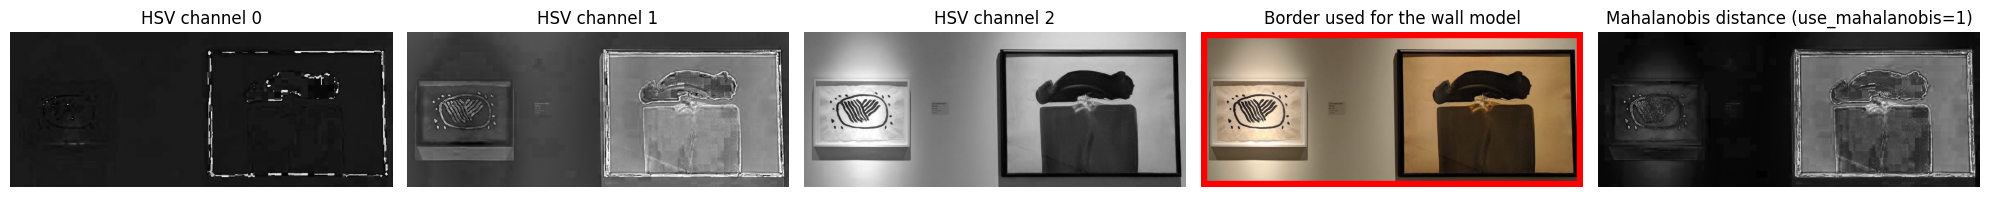

In [ ]:
P = U.DEFAULT_PARAMS
space = cv2.cvtColor(img, U.COLOR_SPACES[P["color_space"]])
names = {"HSV": "HSV", "LAB": "LAB"}[P["color_space"]]

h, w = img.shape[:2]
border_vis = rgb(img).copy()
border_vis[U.border_mask(h, w)] = (255, 0, 0)

show([(f"{names} channel {c}", space[..., c]) for c in range(3)]
     + [("Border used for the wall model", border_vis),
        ("Mahalanobis distance (use_mahalanobis=1)",
         np.clip(U.edge_input(img, P["color_space"], P["channels"], use_mahalanobis=1), 0, 255))],
     cols=5)

## 2. Edges (high-pass filters)
### 2.1 Prewitt gradients
Prewitt kernels approximate the horizontal and vertical derivatives. The magnitude $\sqrt{G_x^2 + G_y^2}$ is high on the painting frames. A small Gaussian blur is applied first so the wall texture does not produce edges. Below, for every channel of the edge input (`use_mahalanobis=0`).

Prewitt Gx kernel:
 [[-1.  0.  1.]
 [-1.  0.  1.]
 [-1.  0.  1.]] 
Prewitt Gy kernel:
 [[-1. -1. -1.]
 [ 0.  0.  0.]
 [ 1.  1.  1.]]


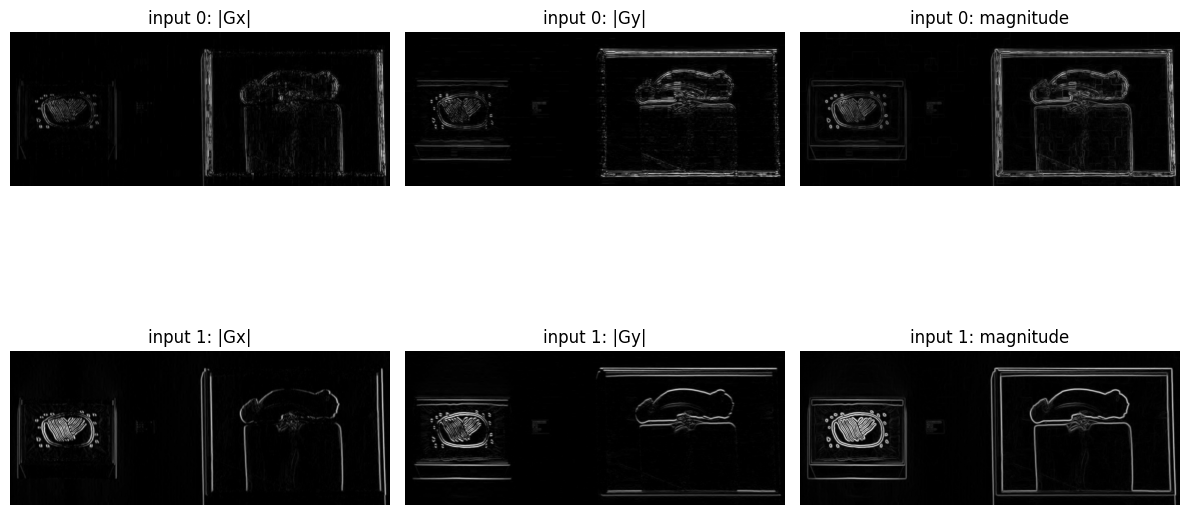

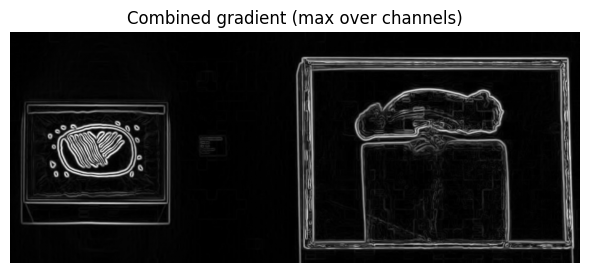

In [ ]:
kx, ky = U.EDGE_KERNELS["prewitt"]
print("Prewitt Gx kernel:\n", kx, "\nPrewitt Gy kernel:\n", ky)

edge_map = debug["edge_input"]
edge_map = edge_map[..., None] if edge_map.ndim == 2 else edge_map
panels = []
for k in range(edge_map.shape[2]):
    ch = cv2.GaussianBlur(edge_map[..., k], (P["blur_ksize"], P["blur_ksize"]), 0)
    gx = cv2.filter2D(ch, cv2.CV_32F, kx)
    gy = cv2.filter2D(ch, cv2.CV_32F, ky)
    panels += [(f"input {k}: |Gx|", np.abs(gx)), (f"input {k}: |Gy|", np.abs(gy)),
               (f"input {k}: magnitude", np.sqrt(gx ** 2 + gy ** 2))]
show(panels, cols=3)
show([("Combined gradient (max over channels)", debug["gradient"])], size=6)

### 2.2 Mahalanobis on vs off, and comparing high-pass operators

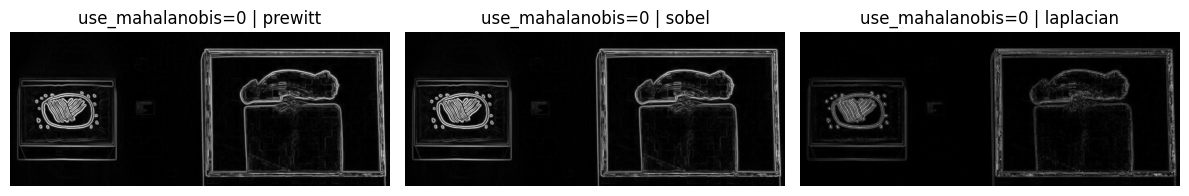

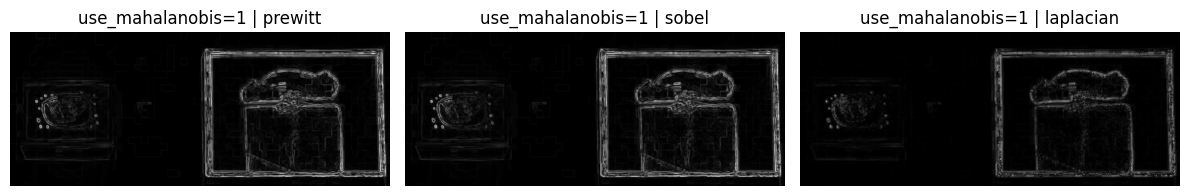

In [ ]:
maps = {m: U.edge_input(img, P["color_space"], P["channels"], use_mahalanobis=m) for m in (0, 1)}
ops = ["prewitt", "sobel", "laplacian"]
for m, emap in maps.items():
    show([(f"use_mahalanobis={m} | {op}", U.gradient_magnitude(emap, op, P["blur_ksize"])) for op in ops])

### 2.3 Binary edges (Otsu + closing)
The magnitude is binarised with Otsu. The closing (`edge_close_frac`) joins the small gaps of each frame, so the outline is closed and its inside can be filled in the next step. Too small → gaps remain and the painting is not filled; too big → nearby structures merge.

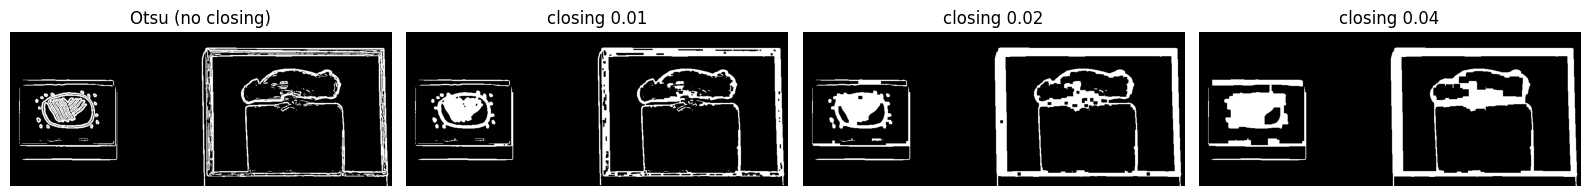

In [ ]:
_, otsu = cv2.threshold(debug["gradient"], 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
closings = [0.01, P["edge_close_frac"], 0.04]
show([("Otsu (no closing)", otsu)]
     + [(f"closing {c}", U.edge_cue(debug["edge_input"], P["edge_operator"], P["blur_ksize"], c)[1])
        for c in closings])

## 3. Week 2 post-processing
Filling the holes turns every closed outline into a solid region. Edges that do not enclose anything stay thin, so the opening removes them (and thin bridges joining two paintings). Holes are filled again at the end.

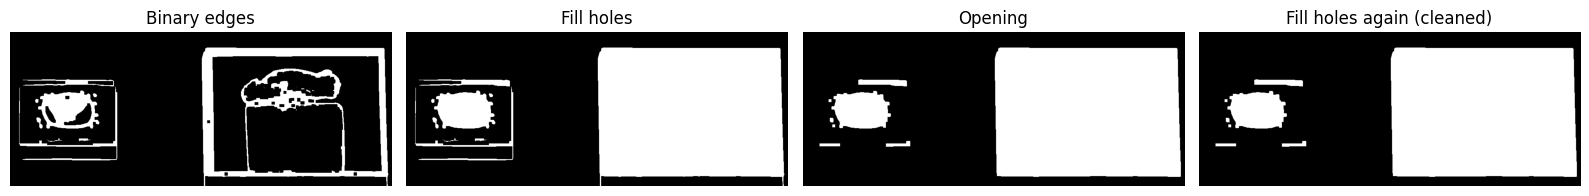

In [ ]:
filled = U.fill_holes(debug["edges"])
opened = U.morph(filled, cv2.MORPH_OPEN, P["open_frac"])
show([("Binary edges", debug["edges"]), ("Fill holes", filled),
      ("Opening", opened), ("Fill holes again (cleaned)", debug["cleaned"])])

## 4. Largest components (Week 2, extended to 2 paintings)
Week 2 kept only the largest connected component. Now every component is a candidate and it is kept if it is big enough (`min_area_frac` of the image), not much smaller than the largest one (`min_rel_area`) and fills its bounding box (extent = area / bbox area ≥ `min_extent`). At most the 2 largest are kept.

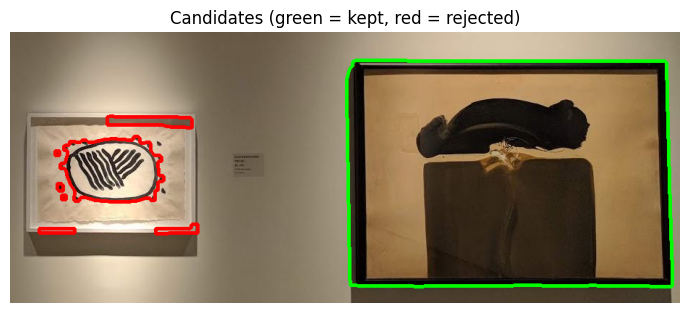

,label,area,extent,bbox,kept,reasons
0,1,138351,0.980080,"[465, 40, 451, 313]",True,[]
2,3,10329,0.788233,"[69, 145, 144, 91]",False,[small vs largest]
1,2,1518,0.756730,"[134, 117, 118, 17]",False,"[too small, small vs largest]"
6,7,490,0.593220,"[201, 266, 59, 14]",False,"[too small, small vs largest, low extent]"
7,8,350,1.000000,"[40, 272, 50, 7]",False,"[too small, small vs largest]"
4,5,93,0.939394,"[65, 210, 9, 11]",False,"[too small, small vs largest]"
3,4,49,1.000000,"[62, 165, 7, 7]",False,"[too small, small vs largest]"
5,6,49,1.000000,"[71, 226, 7, 7]",False,"[too small, small vs largest]"


In [ ]:
cand_vis = rgb(img).copy()
for c in debug["candidates"]:
    color = (0, 255, 0) if c["kept"] else (255, 0, 0)
    contours, _ = cv2.findContours(c["mask"].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(cand_vis, contours, -1, color, 3)
show([("Candidates (green = kept, red = rejected)", cand_vis)], size=7)

pd.DataFrame([{k: v for k, v in c.items() if k != "mask"} for c in debug["candidates"]]) \
    .sort_values("area", ascending=False)

## 5. Shape fitting (Week 2) and ordering
Week 2 converted the mask into a rectangle using its row/column projections: a column (row) is kept if its foreground fraction exceeds `proj_frac` × the maximum. In Week 2 there was only one painting; with two paintings the projections of both would mix (e.g. the rows of a small painting fall below `proj_frac` of the big one). So the rectangle is computed **for each component separately**.

Masks are then ordered left→right (top→bottom if stacked); this order must match the ground-truth order for retrieval.

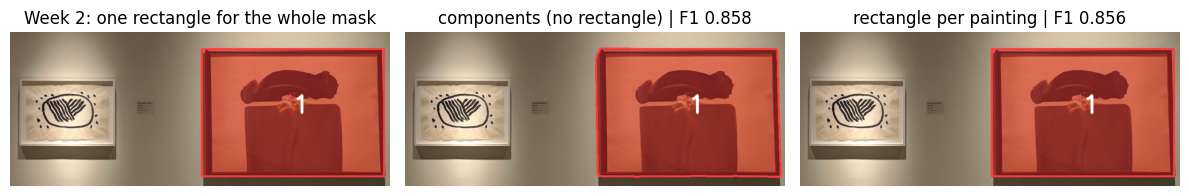

In [ ]:
union = U.combined_mask([c["mask"] for c in debug["candidates"] if c["kept"]], img.shape) > 0
union_rect = U.mask_to_rect(union.astype(np.uint8), P["proj_frac"])
panels = [("Week 2: one rectangle for the whole mask", overlay(img, [union_rect]))]
for fit_rect in (False, True):
    masks = U.detect_paintings(img, fit_rect=fit_rect)
    m = U.metrics(U.combined_mask(masks, img.shape), gt)
    title = "rectangle per painting" if fit_rect else "components (no rectangle)"
    panels.append((f"{title} | F1 {m['f1']:.3f}", overlay(img, masks)))
show(panels)

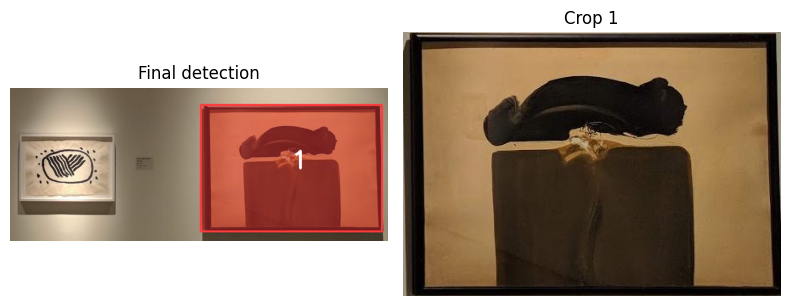

In [ ]:
masks = debug["masks"]
crops = [U.crop_to_mask(img, m) for m in masks]
show([("Final detection", overlay(img, masks))] + [(f"Crop {k + 1}", rgb(c)) for k, c in enumerate(crops)])

## 6. Evaluation on the whole dataset

In [ ]:
def evaluate_all(**params):
    rows, all_masks = [], {}
    for i in ids:
        masks = U.detect_paintings(images[i], **params)
        all_masks[i] = masks
        m = U.metrics(U.combined_mask(masks, images[i].shape), gts[i])
        rows.append({"id": i, "gt_count": n_gt[i], "pred_count": len(masks), **m})
    df = pd.DataFrame(rows).set_index("id")
    df["count_ok"] = df.gt_count == df.pred_count
    return df, all_masks


results, all_masks = evaluate_all()
print(f"Count accuracy: {results.count_ok.sum()}/{len(results)}")
results[["precision", "recall", "f1", "iou", "error_rate"]].mean().to_frame("mean")

Count accuracy: 28/30


,mean
precision,0.966557
recall,0.951386
f1,0.954202
iou,0.919686
error_rate,0.057683


In [ ]:
# Worst images first
results.sort_values("f1").head(10)

,gt_count,pred_count,precision,recall,f1,iou,error_rate,count_ok
id,,,,,,,,
12,2,1,0.991276,0.506118,0.670101,0.503873,0.384626,False
21,1,1,0.984182,0.643048,0.777857,0.636470,0.310837,True
2,2,1,0.959565,0.771805,0.855504,0.747494,0.129186,False
29,2,2,0.817899,0.987728,0.894826,0.809670,0.089000,True
23,1,1,1.000000,0.863810,0.926929,0.863810,0.094271,True
27,1,1,0.937243,0.939022,0.938132,0.883473,0.094063,True
20,1,1,0.945335,0.973574,0.959246,0.921685,0.059681,True
25,1,1,0.923913,1.000000,0.960452,0.923913,0.048994,True
5,2,2,0.934679,1.000000,0.966237,0.934679,0.045976,True


### Gallery of all detections (red title = wrong painting count)

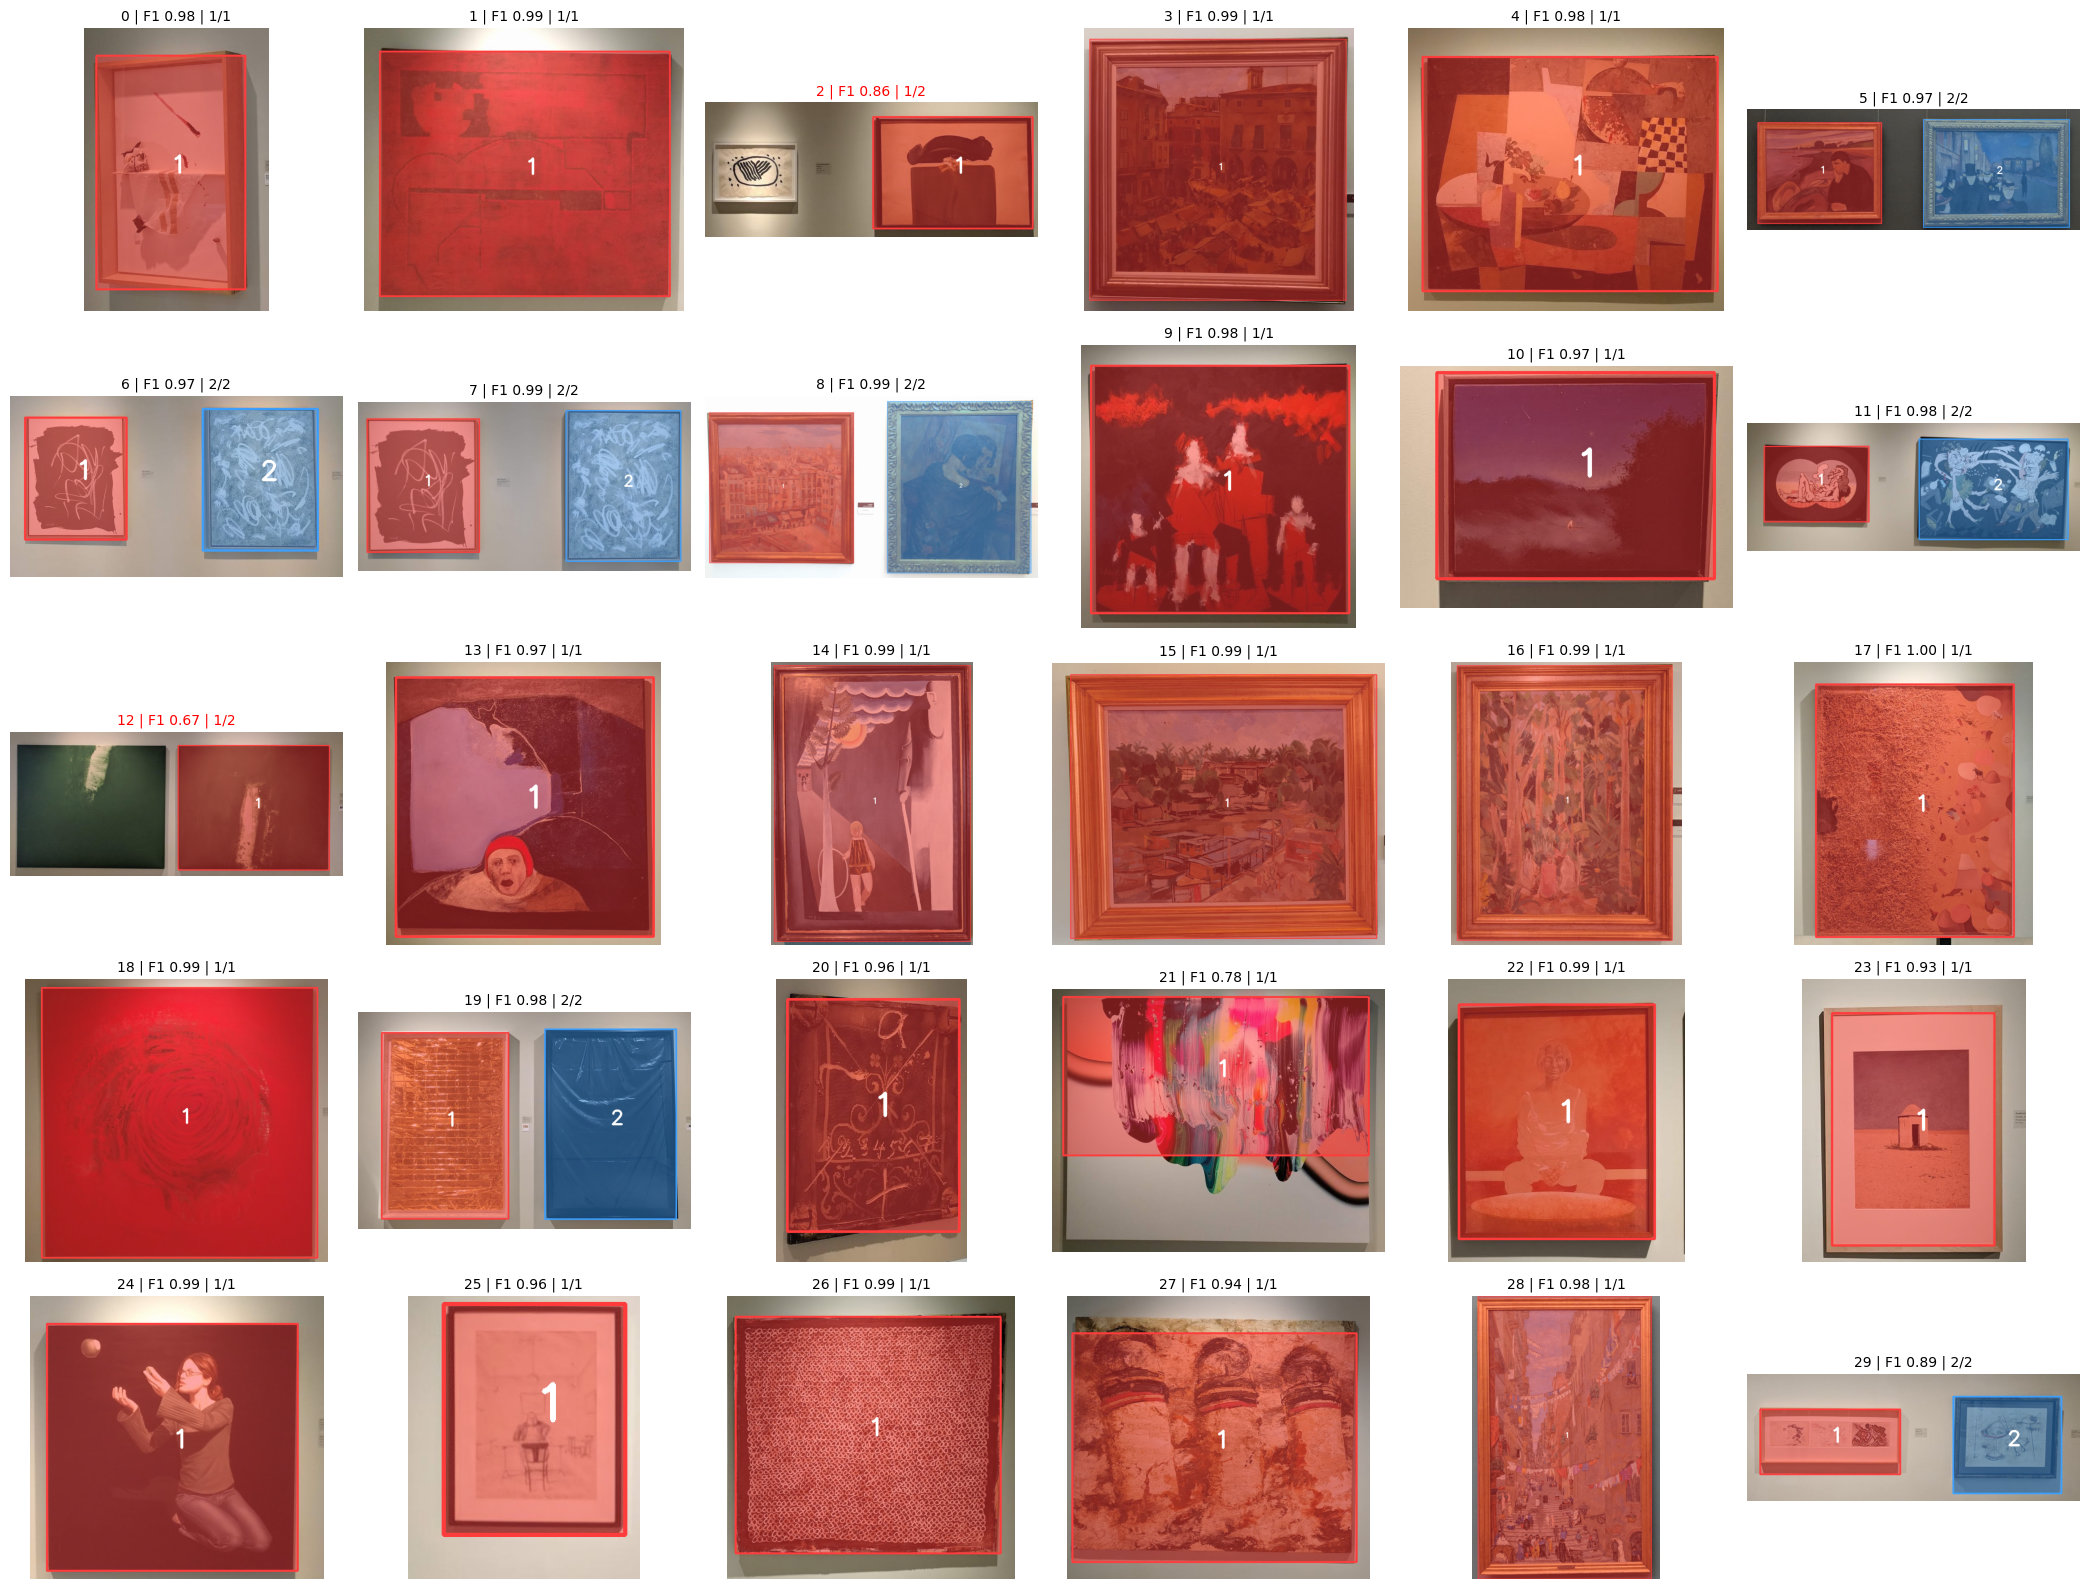

In [ ]:
cols = 6
rows = int(np.ceil(len(ids) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(3.5 * cols, 3.2 * rows))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, ids):
    r = results.loc[i]
    ax.imshow(overlay(images[i], all_masks[i]))
    ax.set_title(f"{i} | F1 {r.f1:.2f} | {r.pred_count}/{r.gt_count}",
                 color="black" if r.count_ok else "red", fontsize=10)
plt.tight_layout()
plt.show()

## 7. Parameter comparison
Each row overrides some of the default parameters. Add your own configurations to `configs` to test new ideas.

In [ ]:
configs = {
    "default (HSV S,V channels)": {},
    "Mahalanobis HSV S,V": {"use_mahalanobis": 1},
    "HSV V only": {"channels": [2]},
    "HSV H,S,V": {"channels": [0, 1, 2]},
    "LAB L,a,b": {"color_space": "LAB", "channels": [0, 1, 2]},
    "LAB L only": {"color_space": "LAB", "channels": [0]},
    "Mahalanobis LAB a,b": {"use_mahalanobis": 1, "color_space": "LAB", "channels": [1, 2]},
    "sobel": {"edge_operator": "sobel"},
    "laplacian": {"edge_operator": "laplacian"},
    "no blur": {"blur_ksize": 1},
    "closing 0.01": {"edge_close_frac": 0.01},
    "closing 0.04": {"edge_close_frac": 0.04},
    "no rectangle fit": {"fit_rect": False},
    "proj_frac 0.3": {"proj_frac": 0.3},
    "proj_frac 0.7": {"proj_frac": 0.7},
}

rows = []
for name, params in configs.items():
    df, _ = evaluate_all(**params)
    rows.append({"config": name, "count_acc": df.count_ok.mean(),
                 **df[["precision", "recall", "f1", "iou"]].mean().to_dict()})
pd.DataFrame(rows).set_index("config").sort_values("f1", ascending=False).style.format("{:.4f}")

,count_acc,precision,recall,f1,iou
config,,,,,
"LAB L,a,b",0.9667,0.9639,0.9722,0.9659,0.9373
no rectangle fit,0.9333,0.9688,0.9515,0.9548,0.9219
proj_frac 0.3,0.9333,0.9596,0.9577,0.9543,0.9190
"default (HSV S,V channels)",0.9333,0.9666,0.9514,0.9542,0.9197
sobel,0.9333,0.9659,0.9510,0.9536,0.9187
closing 0.04,0.9333,0.9529,0.9594,0.9514,0.9138
proj_frac 0.7,0.9333,0.9732,0.9400,0.9497,0.9147
no blur,0.9667,0.9774,0.9187,0.9387,0.8978
laplacian,0.9333,0.9393,0.9221,0.9285,0.8963
